In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Works from the repository root OR from app/L9 in GitHub Codespaces.
def data_file(filename):
    for folder in [Path.cwd(), *Path.cwd().parents]:
        candidate = folder / "data" / filename
        if candidate.exists():
            return candidate
    raise FileNotFoundError(f"Cannot find data/{filename}. Open this notebook inside ProgrammingForDA.")

## Inspect the digit dataset

The 64 pixel columns represent an 8×8 grayscale image. The `digit` column is the correct answer (0–9).

In [2]:
df = pd.read_csv(data_file("handwritten_digits.csv"))
print(df.shape)
print(df["digit"].value_counts().sort_index())
print(df.head(2).iloc[:, :9])

(1797, 65)
digit
0    178
1    182
2    177
3    183
4    181
5    182
6    181
7    179
8    174
9    180
Name: count, dtype: int64
   pixel_0_0  pixel_0_1  pixel_0_2  pixel_0_3  pixel_0_4  pixel_0_5  \
0          0          0          5         13          9          1   
1          0          0          0         12         13          5   

   pixel_0_6  pixel_0_7  pixel_1_0  
0          0          0          0  
1          0          0          0  


## Display one real image

Rebuild the first image from its 64 numerical pixel intensities.

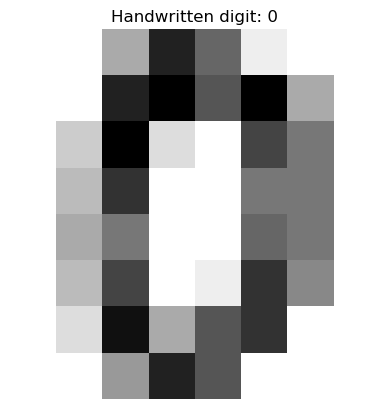

In [3]:
X = df.drop(columns="digit")
y = df["digit"]
plt.imshow(X.iloc[0].to_numpy().reshape(8, 8), cmap="gray_r", interpolation="nearest")
plt.title(f"Handwritten digit: {y.iloc[0]}")
plt.axis("off")
plt.show()

## Reserve a final test set

The final test set must not be used to choose K. We will tune K using cross-validation on training data.

In [4]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1437, 64) Test: (360, 64)


## Compare K using cross-validation

For each K, train and validate on different folds **inside the training data**.

K=1: CV accuracy=0.986
K=3: CV accuracy=0.983
K=5: CV accuracy=0.981
K=7: CV accuracy=0.976
K=9: CV accuracy=0.976


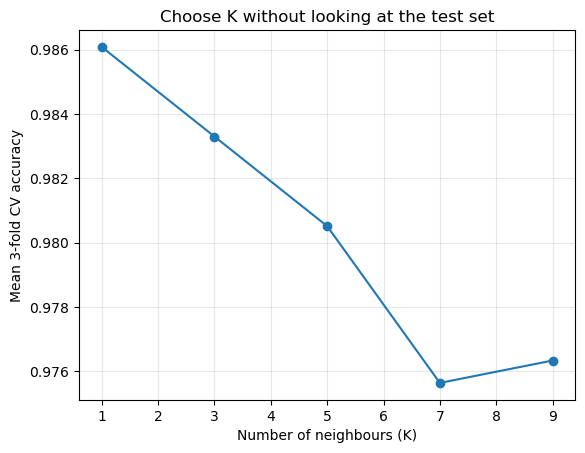

In [5]:
k_values = [1, 3, 5, 7, 9]
cv_scores = []
for k in k_values:
    candidate = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(candidate, X_train, y_train, cv=3).mean()
    cv_scores.append(score)
    print(f"K={k}: CV accuracy={score:.3f}")
plt.plot(k_values, cv_scores, marker="o")
plt.xlabel("Number of neighbours (K)")
plt.ylabel("Mean 3-fold CV accuracy")
plt.title("Choose K without looking at the test set")
plt.grid(alpha=0.3)
plt.show()

## Fit the selected K and evaluate once

Select K by the highest mean cross-validation accuracy, then measure performance on unseen test images.

Chosen K: 1
Held-out test accuracy: 0.986


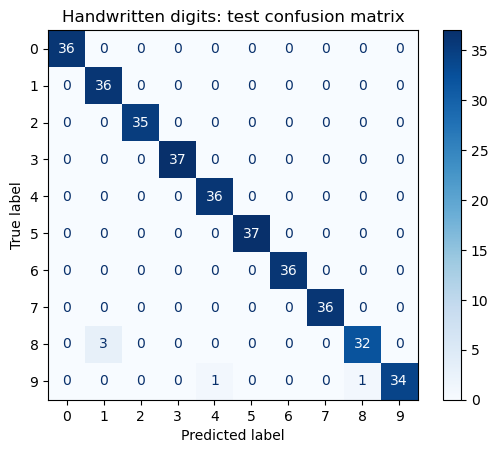

In [6]:
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
best_k = k_values[int(np.argmax(cv_scores))]
model = KNeighborsClassifier(n_neighbors=best_k)
model.fit(X_train, y_train)
predictions = model.predict(X_test)
print("Chosen K:", best_k)
print("Held-out test accuracy:", round(accuracy_score(y_test, predictions), 3))
ConfusionMatrixDisplay.from_predictions(y_test, predictions, cmap="Blues")
plt.title("Handwritten digits: test confusion matrix")
plt.show()

## Your turn — short challenge

Find one misclassified test image, display it, and print the actual and predicted digits. What visual features might explain the mistake?

Try it yourself first. The instructor copy contains a worked answer.

In [7]:
# TODO: write your answer here.
# Hint: reuse the variables created above.